# 03 自动微分应用、线性回归与激活函数


本篇对应 **day03**，是「06-深度学习神经网络」7篇笔记中的第3篇。承接02的张量操作与自动微分，进一步学习detach、自动微分应用、PyTorch线性回归、神经网络结构，以及Sigmoid、Tanh、ReLU和Softmax。

资料：[深度学习神经网络课程资料](https://pan.baidu.com/s/1FPhKS2qMBgnqVOXCyhBTog?pwd=1234)，提取码 `1234`。已核对 `04_深度学习神经网络/视频/day03` 的 **12个视频文件标题**。教师 `课堂笔记.zip` 与 `课件.zip` 正文未取得，视频未逐段转录；本文按目录整理，说明、人工数据、代码与图均为独立编写，不作为教师原文或视频演示的复刻。

延续前篇形式：全部为Markdown单元，Python代码按顺序复制到代码单元即可练习。图全部内嵌在当前Notebook中，阅读不依赖外部图片文件。


## 本篇学习目标

| 对应视频 | 学习内容 | 要能回答的问题 |
| --- | --- | --- |
| 01—02 | detach与自动微分应用 | 如何保留参数的求导能力，又安全更新或导出结果？ |
| 03—05 | 线性回归：数据、训练、可视化 | 参数怎样从误差中学到？如何判断拟合结果？ |
| 06—07 | 神经网络结构与术语 | 输入、隐藏层、输出、权重和偏置分别是什么？ |
| 08—12 | 激活函数与四种常见函数 | 为什么需要非线性？输出范围和梯度有什么区别？ |

本篇先手动更新参数，便于看清“梯度→参数→预测”的关系，再用 `nn.Linear` 对照网络层接口。更完整的参数初始化、网络训练封装、损失函数体系与反向传播推导留给04。


## 1. 环境与代码约定

使用 `torch` 和 `numpy`，本篇全部代码在CPU运行。线性回归数据直接生成，不需要额外下载数据集。图已内嵌，不需要运行绘图代码才能阅读。

```bash
python -m pip install torch numpy
```

```python
import torch
import numpy as np
from torch import nn

torch.manual_seed(2026)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
```

后文沿用这些导入。随机结果由种子、版本和计算设备共同决定；固定种子便于同环境复现，不意味着跨平台永远逐位一致。


## 2. detach：断开梯度路径，不等于复制

第2篇已经说明 `detach()` 的基础用途。day03首先继续处理这个容易混淆的问题：**新变量能否修改，与新变量是否参与梯度计算，是两件事。**

`detach()` 返回脱离当前计算图的张量，但与原张量共享存储。`clone()` 复制数据，但在可求导环境中仍可保留求导关系。若同时要独立存储与断开梯度，用 `detach().clone()`。

```python
parameter = torch.tensor([1.0, 2.0], requires_grad=True)
export_view = parameter.detach()
export_copy = parameter.detach().clone()
assert not export_view.requires_grad
assert export_view.data_ptr() == parameter.data_ptr()
assert export_copy.data_ptr() != parameter.data_ptr()

# 在建图之前展示共享修改；不要修改正在反向传播所需的值
with torch.no_grad():
    export_view[0] = 9.0
assert parameter[0].item() == 9.0
assert export_copy[0].item() == 1.0
```

需要NumPy独立副本时，可用 `parameter.detach().cpu().numpy().copy()`。CPU张量的 `cpu()` 不保证复制；不能因为写了 `detach().cpu()` 就认为数据已独立。


### 2.1 更新参数时，优先在no_grad中保持原参数

普通可求导运算 `new_w=w-lr*w.grad` 会创建新的非叶子结果。反复把新结果绑定为w，容易误读 `w.grad`，也可能把更新步骤接到旧图上。

```python
w = torch.tensor(0.0, requires_grad=True)
loss = (w - 3.0).square()
loss.backward()
new_w = w - 0.1 * w.grad
assert new_w.requires_grad and not new_w.is_leaf

with torch.no_grad():
    w -= 0.1 * w.grad
assert w.is_leaf and w.requires_grad
assert abs(w.item() - 0.6) < 1e-6

# 如果确实要创建新的独立叶子，可显式重建；通常不需要每轮这么做
fresh_leaf = new_w.detach().clone().requires_grad_(True)
assert fresh_leaf.is_leaf and fresh_leaf.grad is None
```

手动训练循环采用原参数原地更新并放在 `no_grad` 中；每轮清梯度、重新前向、重新反向。用 `loss.item()` 记录日志不会改变原loss，但若把返回的Python数字当作损失继续求导，就会丢失求导路径。


## 3. 自动微分在训练中负责哪一步

训练要同时完成四件事：

1. 模型根据输入和当前参数给出预测。
2. 损失函数比较预测与标签。
3. 自动微分计算损失相对参数的梯度。
4. 更新规则根据梯度调整参数。

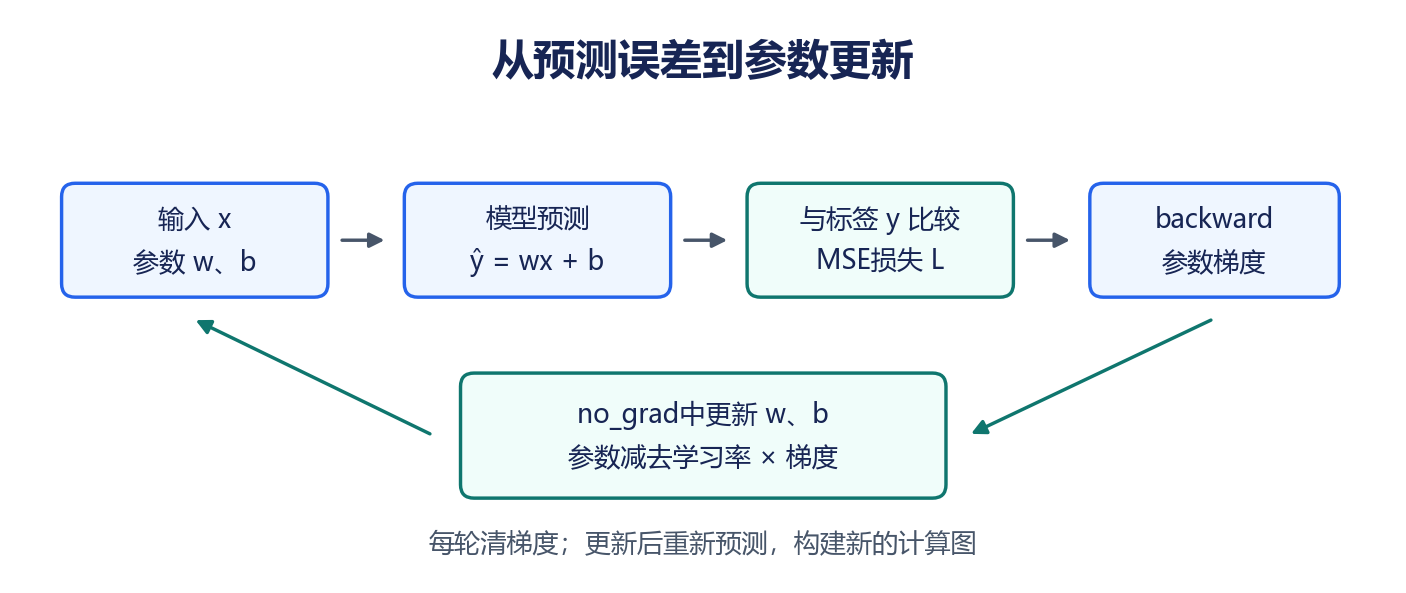

本篇使用线性回归：

$$\hat y_i=wx_i+b.$$

w为斜率，b为截距。它们是需要学习的参数；输入x与标签y通常是固定数据，不需要 `requires_grad=True`。自动微分不会替你选择数据、模型、损失或学习率。


## 4. 准备数据：先把shape与生成规律说清楚

独立示例使用真实生成规律 `y=2x+1+噪声`。生成120个样本，x范围为-3到3，加入标准差0.2的高斯噪声。这里的“真实规律”只因为数据是我们生成的；现实项目通常不知道真实参数。

每个样本只有一个特征，所以输入和标签都采用 `(N,1)`。

```python
data_generator = torch.Generator().manual_seed(2026)
x_all = torch.linspace(-3.0, 3.0, 120).reshape(-1, 1)
noise = 0.2 * torch.randn(x_all.shape, generator=data_generator)
y_all = 2.0 * x_all + 1.0 + noise

assert x_all.shape == y_all.shape == (120, 1)
assert x_all.dtype == y_all.dtype == torch.float32
assert not x_all.requires_grad and not y_all.requires_grad
print(x_all[:3])
print(y_all[:3])
```

为什么加噪声？让例子更接近存在测量误差的数据。即便学到了接近2和1的参数，每个样本也不会都落在拟合直线上，训练损失通常不会降到0。


### 4.1 划分训练集与测试集

将120个样本随机分成96个训练样本和24个测试样本。训练集用于更新参数；测试集留到训练结束再评价，避免直接拿测试标签来调参数。

```python
split_generator = torch.Generator().manual_seed(7)
permutation = torch.randperm(len(x_all), generator=split_generator)
train_indices = permutation[:96]
test_indices = permutation[96:]
x_train, y_train = x_all[train_indices], y_all[train_indices]
x_test, y_test = x_all[test_indices], y_all[test_indices]

assert x_train.shape == y_train.shape == (96, 1)
assert x_test.shape == y_test.shape == (24, 1)
assert len(set(train_indices.tolist()) & set(test_indices.tolist())) == 0
assert torch.equal(torch.sort(permutation).values, torch.arange(120))
print("训练样本:", len(x_train), "测试样本:", len(x_test))
```

本例是同一人工分布中的随机划分，不证明对真实世界的泛化能力。若数据有时间先后、用户重复或设备分组，应按任务选择时间或分组划分，避免泄漏。真实项目需要调超参数时另设验证集。


## 5. 模型与损失：均方误差

本篇手动创建需要梯度的参数w和b：

$$L(w,b)=\frac{1}{N}\sum_{i=1}^{N}(wx_i+b-y_i)^2.$$

`y_hat-y` 是残差，平方后避免正负抵消，最后取均值。平方误差对较大的偏差惩罚更重；均方误差是本例的训练目标，不是“回归准确率”。

```python
weight = torch.tensor(0.0, requires_grad=True)
bias = torch.tensor(0.0, requires_grad=True)
initial_prediction = x_train * weight + bias
assert initial_prediction.shape == y_train.shape
initial_mse = (initial_prediction - y_train).square().mean().item()
print(f"初始训练MSE={initial_mse:.4f}")
```

预测和标签必须shape相同。如果 `prediction=(N,1)` 而 `label=(N,)`，相减可能广播成 `(N,N)`。损失照样能算且能求导，但含义已经错了，因此前向与损失计算之间加shape检查很有价值。


## 6. 先手算一次梯度，再与autograd对照

令残差 `r_i=wx_i+b-y_i`，由链式法则：

$$\frac{\partial L}{\partial w}=\frac{2}{N}\sum_i r_ix_i,\qquad
\frac{\partial L}{\partial b}=\frac{2}{N}\sum_i r_i.$$

用3个无噪声样本 `x=[-1,0,1]、y=[-1,1,3]`，初始w=b=0。初始MSE为11/3，梯度为 `dw=-8/3、db=-2`；学习率0.1更新后，w约0.2667，b=0.2。

```python
tiny_x = torch.tensor([[-1.0], [0.0], [1.0]])
tiny_y = torch.tensor([[-1.0], [1.0], [3.0]])
tiny_w = torch.tensor(0.0, requires_grad=True)
tiny_b = torch.tensor(0.0, requires_grad=True)
tiny_residual = tiny_x * tiny_w + tiny_b - tiny_y
tiny_loss = tiny_residual.square().mean()
tiny_loss.backward()

manual_dw = 2 * (tiny_residual.detach() * tiny_x).mean()
manual_db = 2 * tiny_residual.detach().mean()
assert torch.allclose(tiny_w.grad, manual_dw)
assert torch.allclose(tiny_b.grad, manual_db)
assert abs(tiny_w.grad.item() + 8 / 3) < 1e-6
assert tiny_b.grad.item() == -2.0

with torch.no_grad():
    tiny_w -= 0.1 * tiny_w.grad
    tiny_b -= 0.1 * tiny_b.grad
print(tiny_w.item(), tiny_b.item())
assert (tiny_x * tiny_w + tiny_b - tiny_y).square().mean().item() < tiny_loss.item()
```

自动微分省去了手写复杂梯度的工作，但梯度公式仍能帮助我们检查方向、尺度和实现是否正确。


## 7. 完整训练：两参数全量梯度下降

本例每轮使用全部96个训练样本，属于**全量梯度下降**；没有把单样本更新误称为一个epoch。一次完整遍历训练集算一个epoch，这里每个epoch恰好更新一次参数。

```python
learning_rate = 0.05
epochs = 150
training_log = []

for epoch in range(epochs):
    weight.grad = None
    bias.grad = None

    prediction = x_train * weight + bias
    assert prediction.shape == y_train.shape
    loss = (prediction - y_train).square().mean()
    loss.backward()
    training_log.append({
        "epoch": epoch,
        "mse_before_update": loss.item(),
        "weight_before_update": weight.item(),
        "bias_before_update": bias.item(),
    })

    with torch.no_grad():
        weight -= learning_rate * weight.grad
        bias -= learning_rate * bias.grad

with torch.no_grad():
    fitted_train = x_train * weight + bias
    train_mse = (fitted_train - y_train).square().mean().item()

print(f"w={weight.item():.4f}, b={bias.item():.4f}")
print(f"训练MSE: {initial_mse:.4f} -> {train_mse:.6f}")
assert abs(weight.item() - 2.0) < 0.1
assert abs(bias.item() - 1.0) < 0.1
assert train_mse < 0.08 and train_mse < initial_mse
assert weight.is_leaf and bias.is_leaf
```

清梯度、前向、损失、反向、更新的顺序不可漏。日志保存Python数字，避免保留历史计算图；日志记录更新前状态，训练结束后的MSE另行计算。训练轮数和学习率是本人工例子的选择，不是通用最佳参数。


## 8. 测试集评价与预测

训练结束后，用冻结的当前参数在测试集计算MSE和RMSE。测试过程不需要记录梯度，放在 `torch.no_grad()` 中。

```python
with torch.no_grad():
    test_prediction = x_test * weight + bias
    test_mse = (test_prediction - y_test).square().mean().item()
    test_rmse = test_mse ** 0.5
    query_x = torch.tensor([[-2.0], [0.0], [2.0]])
    query_prediction = query_x * weight + bias

print(f"测试MSE={test_mse:.6f}, RMSE={test_rmse:.4f}")
print(query_prediction)
assert test_prediction.shape == y_test.shape
assert test_mse < 0.1
assert torch.allclose(query_prediction,
                      torch.tensor([[-3.0], [1.0], [5.0]]), atol=0.2)
```

MSE的单位是标签单位的平方，RMSE恢复为标签单位；两者都是越小越好。训练损失低不自动代表测试表现好。这里预测的是噪声数据背后的平均趋势，不是在预测下一次随机噪声。


## 9. 可视化：同时看拟合直线与损失曲线

左图展示训练样本、测试样本、生成规律和训练后的直线；右图展示每次更新前的训练MSE。

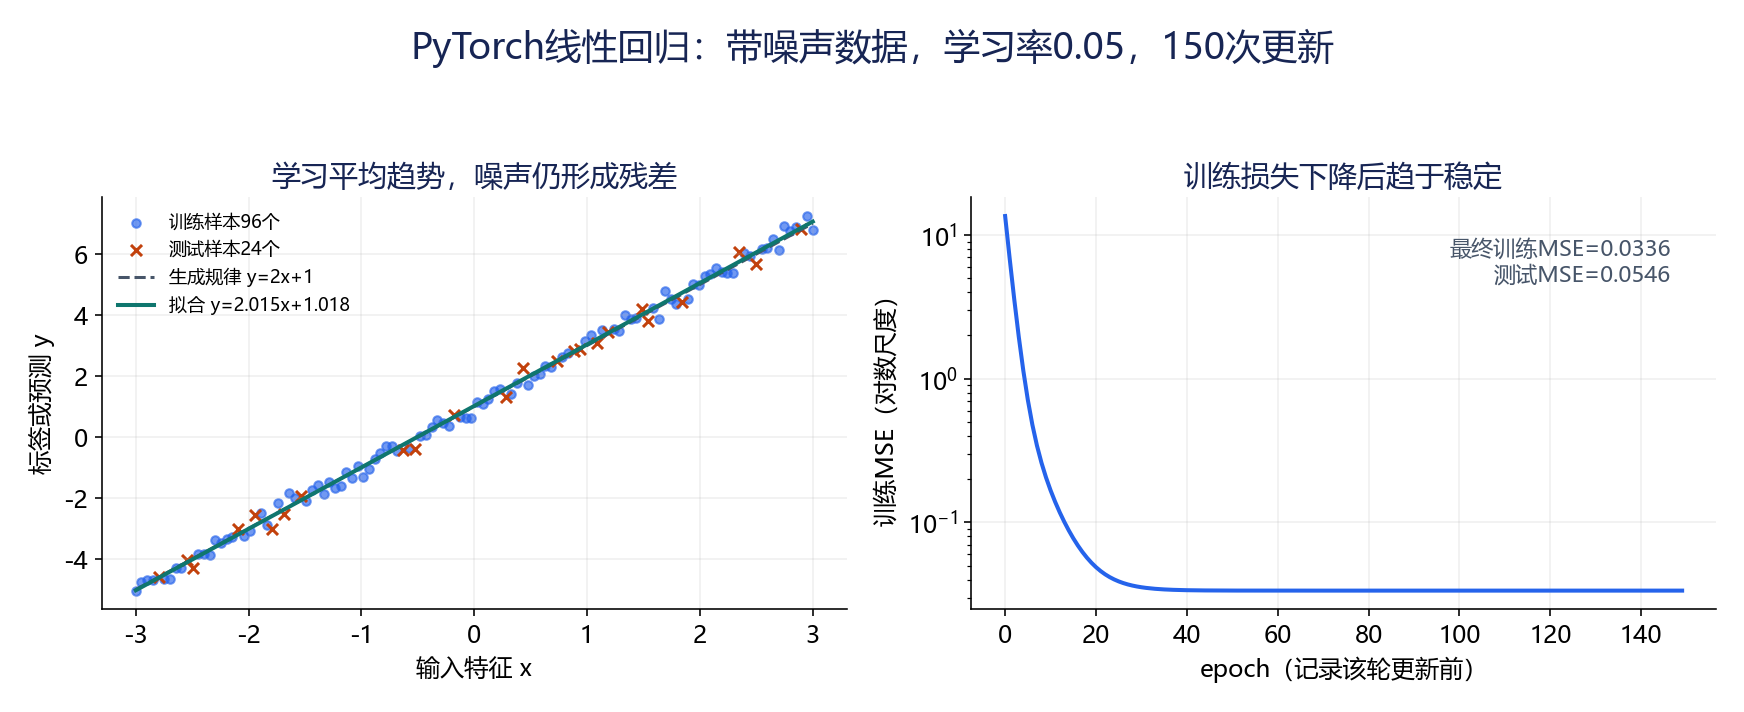

图中的数值来自本篇代码在CPU上的真实运行，使用同一份数据和150次更新结果，不是手画一个“看起来在收敛”的曲线。

若自己绘图，可从数据与参数导出独立数组：

```python
plot_train_x = x_train.detach().cpu().numpy().copy().ravel()
plot_train_y = y_train.detach().cpu().numpy().copy().ravel()
with torch.no_grad():
    sorted_x = torch.linspace(-3.0, 3.0, 200).reshape(-1, 1)
    sorted_prediction = sorted_x * weight + bias
plot_line_x = sorted_x.numpy().ravel()
plot_line_y = sorted_prediction.numpy().ravel()
plot_losses = np.array([row["mse_before_update"] for row in training_log])
assert plot_line_x.shape == plot_line_y.shape == (200,)
assert plot_losses.shape == (150,)
```

散点图可按原顺序绘制；折线应按x排序或直接使用等间隔x，否则线段会来回穿梭。损失趋平后仍有噪声误差，不应一味追求训练损失为0。


## 10. 用nn.Linear理解一层网络

对输入 `X.shape=(N,in_features)`，`nn.Linear(in_features,out_features)` 输出 `(N,out_features)`，内部公式为：

$$Y=XW^{\mathsf T}+b.$$

PyTorch存储的 `weight.shape=(out_features,in_features)`，`bias.shape=(out_features,)`。这与手写 `X@A+b` 时 `A.shape=(in_features,out_features)` 的约定不同；不能只看变量都叫weight就忽略转置。

```python
linear_layer = nn.Linear(1, 1)
with torch.no_grad():
    linear_layer.weight.fill_(weight.item())
    linear_layer.bias.fill_(bias.item())

layer_prediction = linear_layer(query_x)
assert linear_layer.weight.shape == (1, 1)
assert linear_layer.bias.shape == (1,)
assert torch.allclose(layer_prediction.detach(), query_prediction)
assert sum(p.numel() for p in linear_layer.parameters()) == 2
print(linear_layer)
```

这里是把已学参数放入层中做**接口对照**，不是又训练了一次模型。`nn.Linear` 默认带偏置，因此严格说是仿射变换；它自身不包含ReLU等激活。


## 11. 神经元：加权求和，再激活

一个常见人工神经元的计算分两步：

$$z=\sum_{j=1}^{d}w_jx_j+b,\qquad a=\phi(z).$$

z是激活前的值，a是激活后的输出，φ是激活函数。输入特征表达数据，权重表达各特征的影响，偏置允许整体平移。它是简化的数学模型，不等同于真实生物神经元。

```python
sample = torch.tensor([[1.0, 2.0]])
neuron_weight = torch.tensor([0.5, -1.0])
neuron_bias = torch.tensor(0.3)
pre_activation = sample @ neuron_weight + neuron_bias
activation = torch.relu(pre_activation)
assert torch.allclose(pre_activation, torch.tensor([-1.2]))
assert activation.item() == 0.0
print(pre_activation, activation)
```

一个层通常同时计算多个神经元；将神经元的权重组织成矩阵，就可以用矩阵乘法一次处理整批样本。


## 12. 输入层、隐藏层、输出层与参数数目

本例网络有2个输入特征、4个隐藏单元、1个输出。输入层只是数据入口，不像 `nn.Linear` 那样自动带一组可训练参数。隐藏层使用Tanh，输出保留线性值，可用于回归。

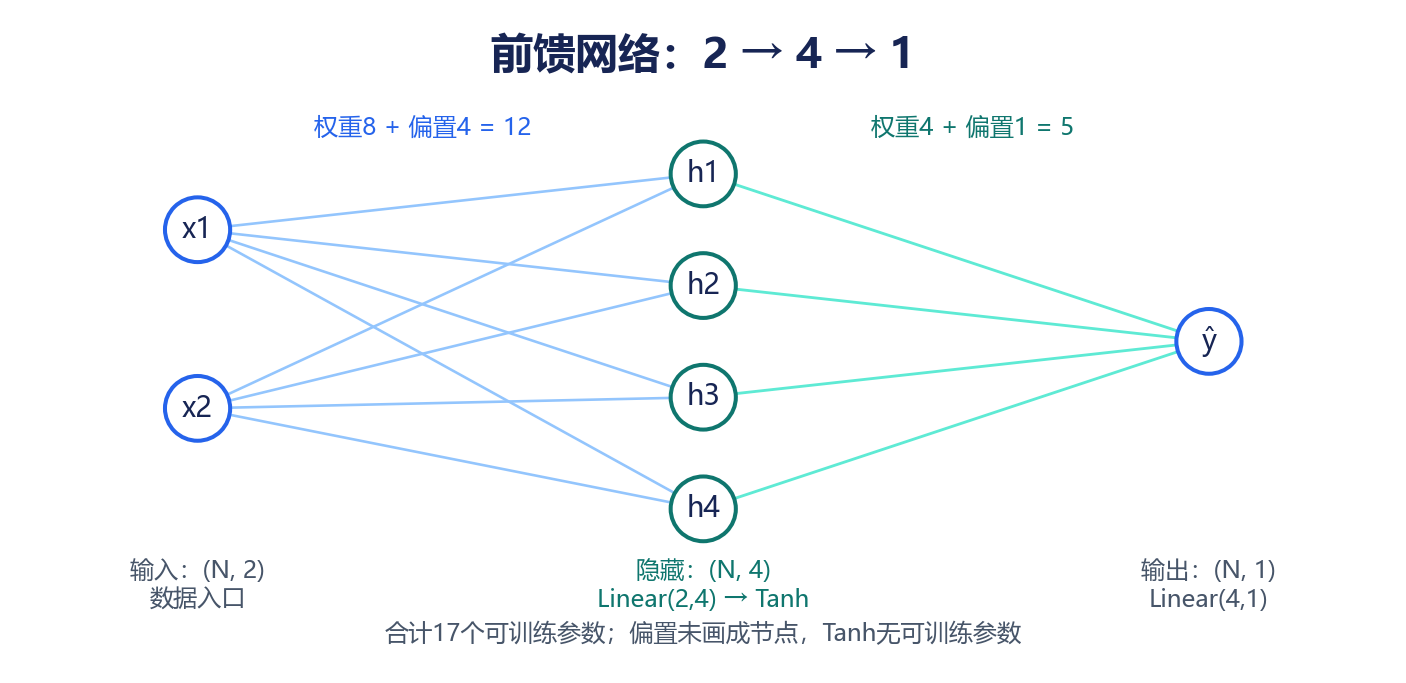

含偏置的全连接层参数数目为 `输入数×输出数+输出数`：

- 2→4：`2×4+4=12`。
- 4→1：`4×1+1=5`。
- 合计17个可训练参数。

```python
torch.manual_seed(2026)
small_network = nn.Sequential(
    nn.Linear(2, 4),
    nn.Tanh(),
    nn.Linear(4, 1),
)
example_batch = torch.tensor([[1.0, 2.0], [3.0, 4.0], [-1.0, 0.0]])
example_output = small_network(example_batch)
assert example_output.shape == (3, 1)
assert sum(p.numel() for p in small_network.parameters()) == 17
for name, parameter in small_network.named_parameters():
    print(name, tuple(parameter.shape), parameter.numel())
```

这是结构和shape演示，模型没有训练，输出不代表学到规律。`nn.Sequential` 按顺序调用各层；激活函数Tanh没有可训练参数。更复杂的分支、跳连等结构通常用 `nn.Module` 自定义，后篇再展开。


## 13. 为什么隐藏层需要非线性

如果两层之间没有非线性激活，那么：

$$H=XA_1+b_1,\quad Y=HA_2+b_2
=X(A_1A_2)+(b_1A_2+b_2).$$

两层可合并成一个仿射变换。堆更多纯线性或仿射层仍不会获得一般的非线性表达能力。

```python
X = torch.tensor([[1.0, 2.0], [-1.0, 3.0]])
A1 = torch.tensor([[1.0, 0.0, 2.0], [0.0, 1.0, -1.0]])
b1 = torch.tensor([0.1, 0.2, 0.3])
A2 = torch.tensor([[1.0], [2.0], [-0.5]])
b2 = torch.tensor([0.4])
two_layers = (X @ A1 + b1) @ A2 + b2
merged_layer = X @ (A1 @ A2) + (b1 @ A2 + b2)
assert torch.allclose(two_layers, merged_layer, atol=1e-6)
print(two_layers)
```

加入非线性后，通常无法再这样合并。隐藏层“变多”与模型“能表达非线性”不是同一个条件；激活函数让多层组合具有更丰富的表达能力。


### 13.1 一个不用训练的XOR表达例子

XOR的四种输入为 `(0,0)、(0,1)、(1,0)、(1,1)`，目标为 `0、1、1、0`。单个仿射输出不能同时精确满足四组值。

令 `s=x1+x2`，在这些离散输入上使用 `ReLU(s)-2ReLU(s-1)`，就能得到目标值：

```python
xor_input = torch.tensor([[0.0, 0.0], [0.0, 1.0],
                          [1.0, 0.0], [1.0, 1.0]])
xor_target = torch.tensor([[0.0], [1.0], [1.0], [0.0]])
summed = xor_input.sum(dim=1, keepdim=True)
xor_output = torch.relu(summed) - 2 * torch.relu(summed - 1)
assert torch.equal(xor_output, xor_target)
print(xor_output)
```

这里的权重是人为指定的，只用于说明非线性表达能力，未展示“模型自动学会XOR”。该公式在四个离散输入上成立，不是对任意输入都返回0—1概率的分类器。


## 14. 激活函数的四个观察角度

选择激活函数时，至少看四个方面：

1. **输出范围**：是否需要负数、0—1数值或不受限输出？
2. **非线性**：是否能打破多层仿射变换可合并的问题？
3. **梯度**：大输入时是否容易饱和，负输入时是否有梯度？
4. **所在位置**：隐藏层与输出层的目的可能不同。

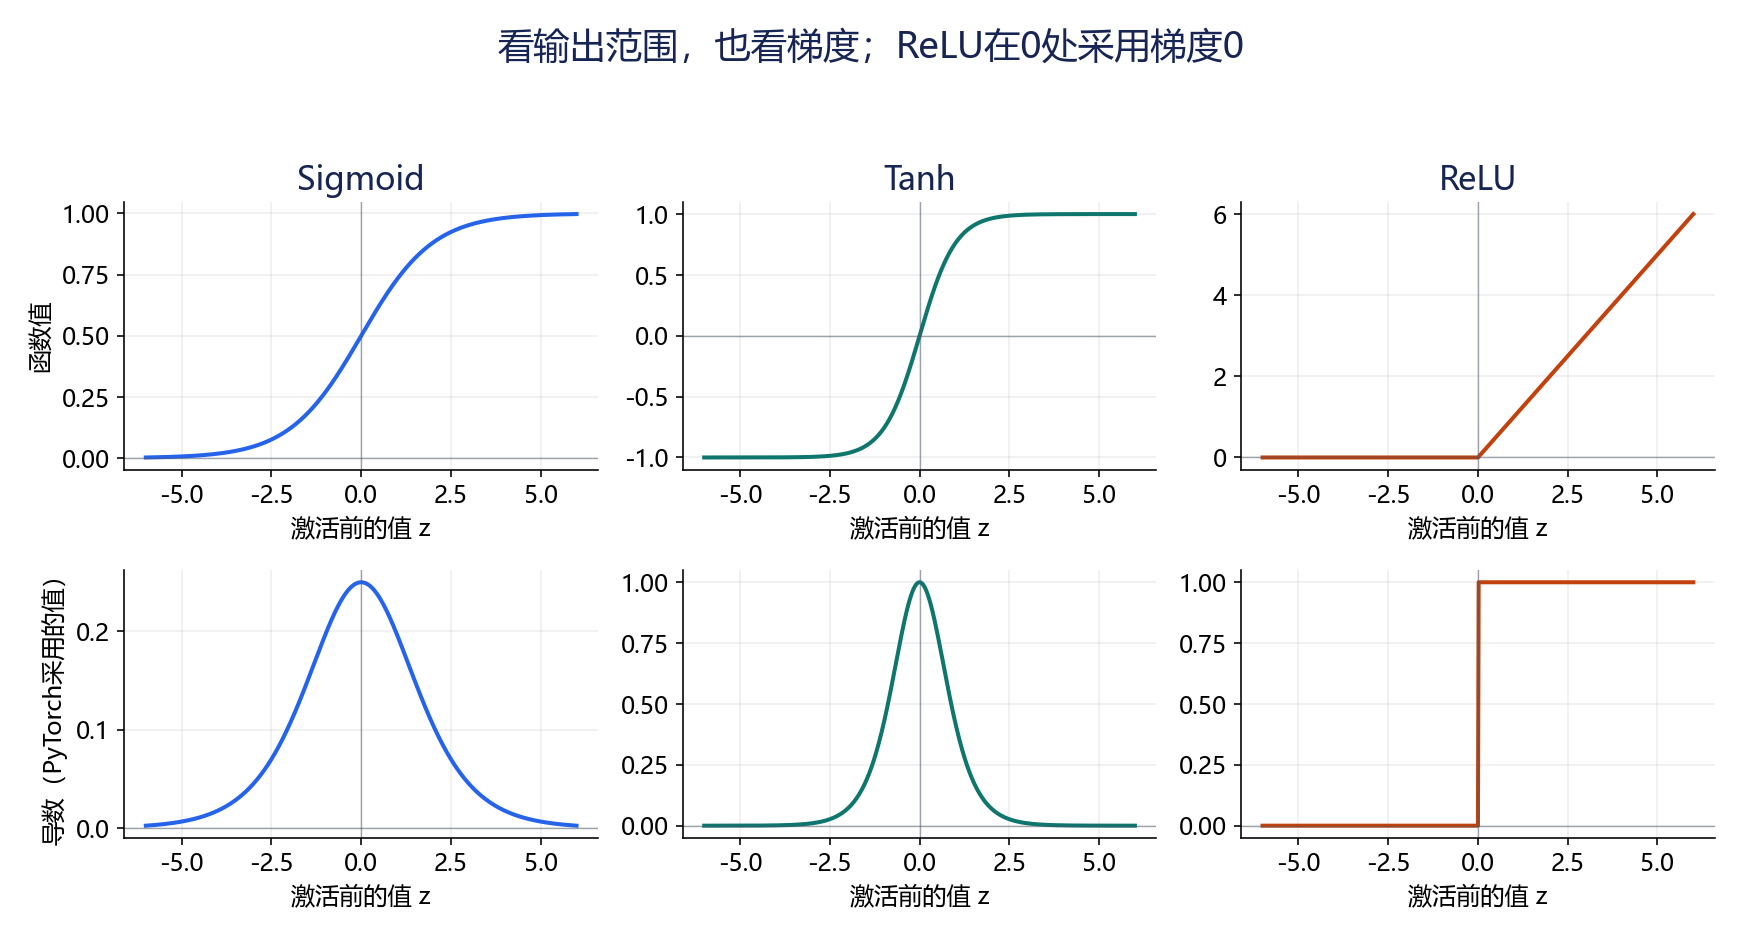

图中Sigmoid和Tanh远离0后逐渐饱和，导数变小；ReLU负半轴为0，正半轴斜率为1。ReLU在0不可微，PyTorch的自动微分在该点采用梯度0。

Softmax针对一组类别分数共同计算，不是每个元素各自独立的普通标量函数，因此后面单独讲解它的类别轴、归一化和相互影响。


## 15. Sigmoid：压到0与1之间

$$\sigma(z)=\frac{1}{1+e^{-z}},\qquad
\sigma'(z)=\sigma(z)(1-\sigma(z)).$$

有限实数输入的数学输出位于 `(0,1)`，且 `σ(0)=0.5`；浮点数在极端输入时可能舍入到0或1。导数最大值为0.25，出现在0附近。

```python
sigmoid_input = torch.tensor([-6.0, -1.0, 0.0, 1.0, 6.0],
                              requires_grad=True)
sigmoid_output = torch.sigmoid(sigmoid_input)
sigmoid_output.sum().backward()
expected_sigmoid_grad = sigmoid_output.detach() * (1 - sigmoid_output.detach())
assert torch.allclose(sigmoid_input.grad, expected_sigmoid_grad, atol=1e-6)
assert sigmoid_output[2].item() == 0.5
assert sigmoid_input.grad[2].item() == 0.25
assert sigmoid_input.grad[0].item() < 0.003
print(sigmoid_output.detach())
print(sigmoid_input.grad)
```

Sigmoid常用于单标签二分类的输出解释或多个独立二分类输出，也用于某些门控结构。它不是所有隐藏层的默认最佳选择：两端饱和时梯度小，输出还不是以0为中心。

常见二分类训练使用 `BCEWithLogitsLoss`，接收原始分数logits并在内部稳定处理Sigmoid与损失；不要先Sigmoid后再喂给这个损失。推理时可对logits使用Sigmoid解释为概率形式；概率是否可靠还取决于训练和校准。


## 16. Tanh：以0为中心的压缩

$$\tanh(z)=\frac{e^z-e^{-z}}{e^z+e^{-z}},\qquad
\frac{d\tanh(z)}{dz}=1-\tanh^2(z).$$

输出范围为 `(-1,1)`，`tanh(0)=0`，导数在0处为1。相比Sigmoid，Tanh可以表达负输出，且以0为中心；但两端仍会饱和，深层网络仍可能出现梯度变小。

```python
tanh_input = torch.tensor([-3.0, -1.0, 0.0, 1.0, 3.0],
                           requires_grad=True)
tanh_output = torch.tanh(tanh_input)
tanh_output.sum().backward()
expected_tanh_grad = 1 - tanh_output.detach().square()
assert torch.allclose(tanh_input.grad, expected_tanh_grad, atol=1e-6)
assert tanh_output[2].item() == 0.0
assert tanh_input.grad[2].item() == 1.0
assert tanh_input.grad[0].item() < 0.01
assert torch.allclose(tanh_output.detach(), -tanh_output.detach().flip(0))
print(tanh_output.detach())
print(tanh_input.grad)
```

Tanh可用于一些隐藏层和循环网络结构。是否比ReLU更适合，应结合网络、输入范围和训练结果判断，不能只因导数在0处更大就认定全局更好。


## 17. ReLU：正半轴保留，负半轴归零

$$\operatorname{ReLU}(z)=\max(0,z).$$

当z>0时导数为1，z<0时导数为0；z=0在数学上不可微，PyTorch采用0。ReLU在正半轴不饱和，计算简单，广泛用于隐藏层，但输出没有上界，也不能直接当成类别概率。

```python
relu_input = torch.tensor([-2.0, -0.5, 0.0, 0.5, 2.0],
                           requires_grad=True)
relu_output = torch.relu(relu_input)
relu_output.sum().backward()
assert torch.equal(relu_output.detach(), torch.tensor([0., 0., 0., 0.5, 2.]))
assert torch.equal(relu_input.grad, torch.tensor([0., 0., 0., 1., 1.]))
print(relu_output.detach())
print(relu_input.grad)
```

如果一个单元长期对全部样本得到负的激活前值，通过该单元的梯度可能一直为0，出现“死亡ReLU”现象。初始化、学习率与输入分布都会影响它；不等于某一个样本的输出为0就说明神经元死亡。

一种改进是LeakyReLU，在负半轴保留小斜率，例如 `nn.LeakyReLU(negative_slope=0.01)`。本篇只介绍思路，参数初始化和训练策略在后篇展开。


## 18. Softmax：一组类别分数共同归一化

对C个类别的logits z：

$$p_i=\frac{e^{z_i}}{\sum_{j=1}^{C}e^{z_j}}.$$

Softmax沿选定轴归一化，该轴上的概率和为1。对于 `logits.shape=(N,C)`，常用 `dim=1` 或 `dim=-1`，含义是对每个样本的C个类别归一化。

```python
logits = torch.tensor([[2.0, 1.0, 0.1],
                       [0.0, 0.0, 0.0]])
probabilities = torch.softmax(logits, dim=1)
assert probabilities.shape == logits.shape
assert torch.allclose(probabilities.sum(dim=1), torch.ones(2))
assert torch.allclose(probabilities[1], torch.full((3,), 1 / 3))
assert torch.equal(probabilities.argmax(dim=1), logits.argmax(dim=1))
print(probabilities)
print(probabilities.argmax(dim=1))
```

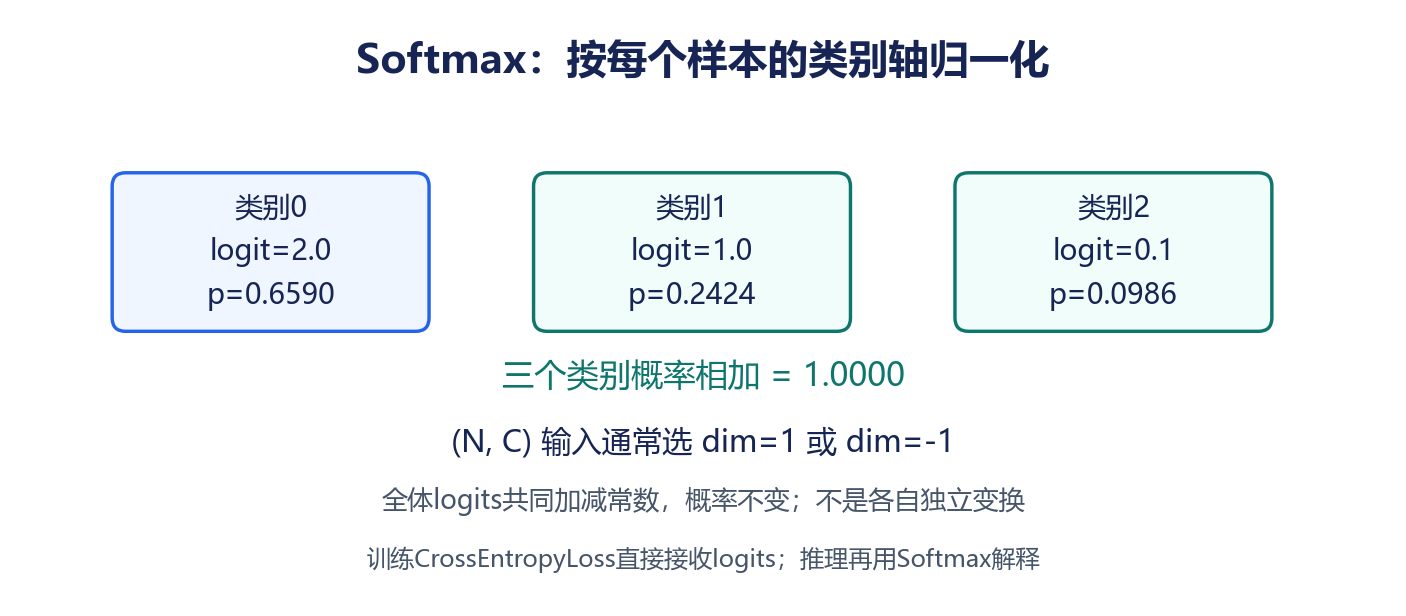

`dim=0` 会跨样本归一化，仍能得到数值，却通常不符合分类目标。Softmax输出类别竞争的归一化分数；高概率不自动等于校准良好的置信度，多标签任务通常不使用“一行总和为1”的约束。


### 18.1 数值稳定：先减去每组最大值

直接 `exp(1000)` 很容易溢出。对同一组所有logits减去相同常数不会改变Softmax，因此常用减去该组最大值：

$$p_i=\frac{e^{z_i-m}}{\sum_j e^{z_j-m}},\quad m=\max_j z_j.$$

```python
large_logits = torch.tensor([[1000.0, 1001.0, 999.0]])
naive_probabilities = large_logits.exp() / large_logits.exp().sum(dim=1, keepdim=True)
assert not torch.isfinite(naive_probabilities).all()

shifted = large_logits - large_logits.max(dim=1, keepdim=True).values
stable_manual = shifted.exp() / shifted.exp().sum(dim=1, keepdim=True)
stable_api = torch.softmax(large_logits, dim=1)
assert torch.isfinite(stable_api).all()
assert torch.allclose(stable_manual, stable_api, atol=1e-6)
assert torch.allclose(torch.softmax(large_logits + 100.0, dim=1), stable_api)
print(stable_api)  # 约[0.2447,0.6652,0.0900]
```

实际代码优先使用 `torch.softmax`、`torch.log_softmax` 等稳定接口，而不是手写指数除法。这里故意展示不稳定写法，是为了观察错误来源。


### 18.2 Softmax不是独立逐元素变换

一个logit变化会影响同组其他类别概率，导数为：

$$\frac{\partial p_i}{\partial z_j}=p_i(\delta_{ij}-p_j).$$

其中i=j时δ为1，否则为0。对 `p0` 求导时，提升 `z0` 会提升 `p0`，提升其他logit则会压低 `p0`。

```python
scores = torch.tensor([2.0, 1.0, 0.1], requires_grad=True)
softmax_values = torch.softmax(scores, dim=0)
softmax_values[0].backward()
expected_gradient = -softmax_values[0].detach() * softmax_values.detach()
expected_gradient[0] += softmax_values[0].detach()
assert torch.allclose(scores.grad, expected_gradient, atol=1e-6)
assert scores.grad[0] > 0 and torch.all(scores.grad[1:] < 0)
assert abs(scores.grad.sum().item()) < 1e-6
print(scores.grad)
```

不能对 `softmax(...).sum()` 的梯度大小来判断分类是否容易训练，因为同组概率之和恒为1，对这项常量求导会得到接近0的结果。分类训练应使用合适的目标损失。


## 19. 输出层与损失函数要配套

本篇只给出常用组合，具体损失函数在04继续展开。

| 任务 | 输出层数值 | 训练时常见损失 | 推理时解释 |
| --- | --- | --- | --- |
| 普通实数回归 | 线性输出，通常不限制范围 | MSELoss等 | 直接预测数值 |
| 单标签二分类 | 1个logit | BCEWithLogitsLoss | Sigmoid后解释为正类概率形式 |
| C类单标签分类 | C个logits | CrossEntropyLoss | Softmax看各类概率，argmax选类别 |
| 多标签分类 | C个独立logits | BCEWithLogitsLoss | 每类独立Sigmoid，可同时为多个正类 |

对常见整数类别标签，`CrossEntropyLoss` 输入为 `(N,C)` 浮点logits，标签为 `(N,)` 的long，类别索引在0到C-1。它内部包含稳定的log-softmax与负对数似然处理，不需要事先做Softmax。

```python
classification_logits = torch.tensor([[2.0, 1.0, 0.1],
                                        [0.2, 1.5, -0.5]], requires_grad=True)
class_targets = torch.tensor([0, 1], dtype=torch.long)
ce_loss = nn.CrossEntropyLoss()(classification_logits, class_targets)
log_probability = torch.log_softmax(classification_logits, dim=1)
manual_ce = -log_probability[torch.arange(2), class_targets].mean()
assert torch.allclose(ce_loss, manual_ce)
ce_loss.backward()
assert classification_logits.grad.shape == (2, 3)
assert torch.isfinite(classification_logits.grad).all()
print(ce_loss.item())
```

把已经归一化的概率再次当logits交给CrossEntropyLoss，往往不会报错，却改变了目标。也不要对每个隐藏层都加Softmax；隐藏表示和最终类别分布承担不同职责。


## 20. 激活函数速查

| 函数 | 数学输出范围 | 0点输出 | 梯度特点 | 常见用途 |
| --- | --- | --- | --- | --- |
| Sigmoid | (0,1) | 0.5 | 最大0.25，两端饱和 | 二分类/多标签输出解释、门控 |
| Tanh | (-1,1) | 0 | 0处为1，两端饱和 | 某些隐藏层、循环结构 |
| ReLU | [0,+∞) | 0 | 正侧1，负侧0；PyTorch在0取0 | 常见隐藏层 |
| Softmax | 一组非负概率，和为1 | 全部logits为0时每类1/C | 类别之间相互耦合 | 多类单标签输出解释 |

函数形式与层形式通常都可使用，例如 `torch.relu(x)` 和 `nn.ReLU()(x)`。层形式便于放进Sequential，函数形式便于在自定义前向中调用。

```python
activation_probe = torch.tensor([-1.0, 0.0, 1.0])
assert torch.equal(torch.sigmoid(activation_probe), nn.Sigmoid()(activation_probe))
assert torch.equal(torch.tanh(activation_probe), nn.Tanh()(activation_probe))
assert torch.equal(torch.relu(activation_probe), nn.ReLU()(activation_probe))
assert torch.equal(torch.softmax(activation_probe, dim=0),
                   nn.Softmax(dim=0)(activation_probe))
print("四种函数形式与层形式的输出已对照")
```

表格给出数学范围；极端输入下有限精度可能出现舍入。选择函数时同时考虑输出意义与梯度，不能只凭一张曲线判断模型效果。


## 21. 常见问题与排查

| 表现或误区 | 检查与处理 |
| --- | --- |
| detach之后修改结果影响参数 | detach共享存储；需要独立数据用detach().clone() |
| 重新赋值w后grad变成None | 检查w是否变为非叶子；参数更新放no_grad中 |
| 每轮loss都有梯度却训练不对 | 检查是否清梯度、是否真正更新参数、是否重复使用旧预测 |
| 标签和预测相减后变成矩阵 | 检查 `(N,1)` 与 `(N,)` 的误广播 |
| MSE不为0就是失败 | 噪声、模型误差与训练状态都可能形成残差 |
| 测试误差用于反复调参 | 另设验证集，最终测试保留到最后 |
| 拟合折线像乱线 | x未排序，或使用了随机样本顺序连线 |
| 多层Linear无激活就能表达任意曲线 | 多层仿射可合并，需引入非线性 |
| nn.Linear默认包含激活 | 不包含；激活单独添加 |
| 参数数目只计算权重 | 默认还需加偏置 |
| Sigmoid输出0—1就保证概率可靠 | 还需训练质量、分布与校准支持 |
| ReLU输出0说明神经元已死亡 | 单样本为0正常；要看是否长期对全部输入负激活 |
| Softmax给出了数值但每行不和为1 | 检查dim是否沿类别轴 |
| 手写exp后出现NaN | 数值溢出，使用稳定Softmax/log_softmax |
| CrossEntropyLoss之前再Softmax | 直接输入原始logits，避免重复归一化 |
| 多标签强制所有类别概率和为1 | 通常每类独立Sigmoid，选择配套损失 |

遇到训练异常，先确认数据shape与标签意义，再看loss数值和参数是否改变，最后检查梯度链路及学习率。不要只用“加深网络”或“多跑几轮”处理所有问题。


## 22. 练习与参考答案

1. w=1、b=0，样本x=2、y=5，单样本平方损失是多少，两个梯度是多少？  
   **答：**预测2，残差-3，损失9；dw=2×(-3)×2=-12，db=2×(-3)=-6。
2. 为什么不能拿 `loss.item()` 的结果继续调用backward？  
   **答：**它是Python数字，不携带计算图；对原loss张量反向。
3. 网络结构3→5→2，两个Linear都带bias，共多少参数？  
   **答：**`3×5+5+5×2+2=32`，激活函数通常不添加参数。
4. 为什么仅堆叠两个Linear仍然是仿射变换？  
   **答：**矩阵乘法和偏置能合并；中间没有非线性。
5. `logits.shape=(8,4)` 的4分类任务，Softmax沿哪个轴？  
   **答：**`dim=1` 或 `dim=-1`，按每个样本的4个类别归一化。
6. Sigmoid、Tanh和ReLU在0处的输出分别是什么？  
   **答：**0.5、0、0；PyTorch在0处的梯度分别为0.25、1、0。
7. 三分类CrossEntropyLoss常见整数标签shape与dtype是什么？  
   **答：**`(N,)` 与long，类别索引0、1、2；输入是 `(N,3)` 的logits。

```python
exercise_w = torch.tensor(1.0, requires_grad=True)
exercise_b = torch.tensor(0.0, requires_grad=True)
exercise_loss = (exercise_w * 2 + exercise_b - 5).square()
exercise_loss.backward()
assert exercise_loss.item() == 9.0
assert exercise_w.grad.item() == -12.0
assert exercise_b.grad.item() == -6.0

exercise_net = nn.Sequential(nn.Linear(3, 5), nn.ReLU(), nn.Linear(5, 2))
assert sum(p.numel() for p in exercise_net.parameters()) == 32
exercise_logits = torch.arange(32, dtype=torch.float32).reshape(8, 4)
assert torch.allclose(torch.softmax(exercise_logits, dim=1).sum(dim=1),
                      torch.ones(8), atol=1e-6)
print("梯度、参数数量与类别轴均已核对")
```


## 23. day03目录与来源范围

| 编号 | 已核对的视频主题 | 对应笔记 |
| --- | --- | --- |
| 01 | 自动微分小问题_detach函数 | 第2节 |
| 02 | 自动微分真实应用场景 | 第3、6—8节 |
| 03 | PyTorch模拟线性回归_准备数据集 | 第4—5节 |
| 04 | PyTorch模拟线性回归_模型训练 | 第6—8节 |
| 05 | PyTorch模拟线性回归_可视化操作 | 第9节 |
| 06 | 如何构建神经网络(neural network) | 第10—13节 |
| 07 | 神经网络_文字介绍 | 第11—13节 |
| 08 | 激活函数介绍 | 第13—14节 |
| 09 | Sigmoid激活函数介绍 | 第15节 |
| 10 | Tanh激活函数介绍 | 第16节 |
| 11 | ReLU激活函数介绍 | 第17节 |
| 12 | Softmax激活函数介绍 | 第18—20节 |

来源范围为网盘视频文件名核对。未读取教师笔记和课件正文，未逐段转录视频。带噪声线性回归、训练测试划分、XOR表达例子、稳定Softmax和损失配套说明均为独立教学示例或补充，不声称与课程中的具体数值、代码和讲解完全相同。

延伸查阅：[autograd文档](https://docs.pytorch.org/docs/stable/autograd.html)、[nn.Linear](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html)、[激活函数模块](https://docs.pytorch.org/docs/stable/nn.html#non-linear-activations-weighted-sum-nonlinearity)、[CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)。本篇API行为由实际CPU运行核对，链接供进一步查阅。

全部图为本文自绘并作为Notebook附件存储，没有单独图片依赖。下一篇按day04继续参数初始化、网络搭建与训练、损失函数和反向传播。

本次验证环境：Python 3.13.7、PyTorch 2.14.1+cpu、NumPy 2.3.3、CPU。顺序执行 24 段Python代码通过，5张图均内嵌为附件；线性回归梯度、训练测试划分、拟合参数、网络参数数目、激活函数与Softmax数值均已核对。拟合参数还与训练集最小二乘解对照，绘图数值与示例实际运行一致。未在GPU上验证。
